In [2]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar

In [3]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [4]:
ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

# Load datasets
ds_clims = []
compute_climatology = False
if compute_climatology:
    for experiment in experiments:
        print(experiment)
        print(f'{base_path}/{experiment}/tot/TKE_monthly_2.5x2.5_2-51.nc')
        tke = flip_and_append(xr.open_mfdataset(f'{base_path}/{experiment}/tot/TKE_monthly_2.5x2.5_2-51.nc',
                                                parallel=True,
                                                chunks={'time': 30}))['tke'].loc[:,250,:,:].mean('time')
        tke_std = (flip_and_append(xr.open_mfdataset(f'{base_path}/{experiment}/tot/TKE_monthly_2.5x2.5_2-51.nc',
                                                parallel=True,
                                                chunks={'time': 30}))['tke'].loc[:,250,:,:].std('time')/np.sqrt(2*12*50)).rename('tke_std')
        dw_lwa = xr.open_mfdataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['dw_lwa'].mean('time')
        dw_lwa_std = (xr.open_mfdataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['dw_lwa'].std('time')/np.sqrt(2*365*50)).rename('dw_lwa_std')
        print(tke_std.shape,tke.shape,dw_lwa_std.shape,dw_lwa.shape)
        ds = xr.merge([tke,dw_lwa,tke_std,dw_lwa_std])
        ds.to_netcdf(f'{base_path}/{experiment}/TKE_dw_lwa_CLIM_1.5x1.5.nc')
        ds_clims.append(ds)
else:
    for experiment in experiments:
        ds = xr.open_dataset(f'{base_path}/{experiment}/TKE_dw_lwa_CLIM_1.5x1.5.nc')
        ds_clims.append(ds)

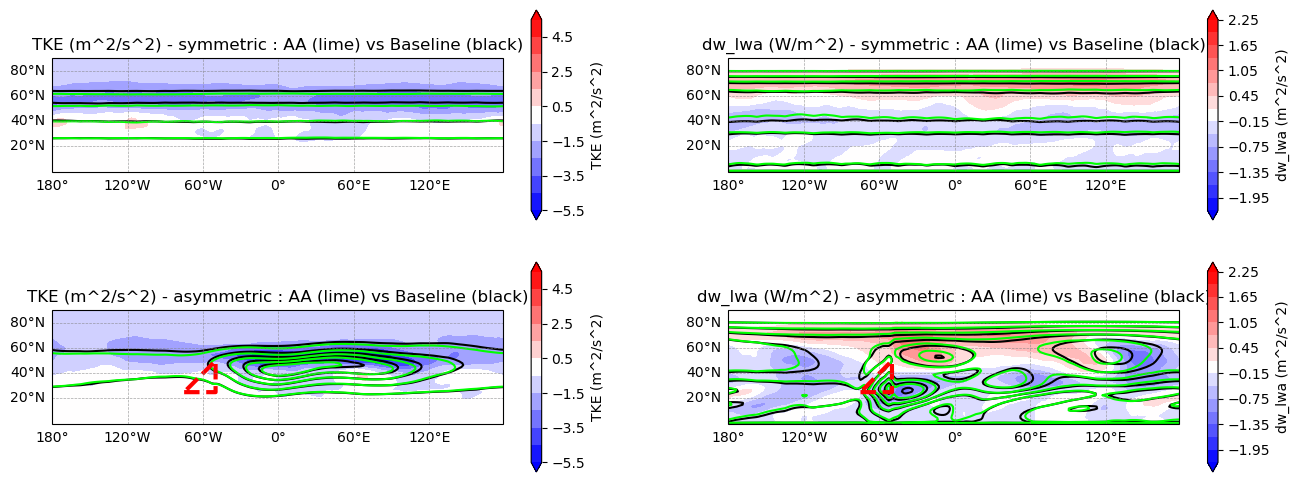

In [5]:
# Initialize a 2-axis figure with Cartopy projection
fig, ax = plt.subplots(2, 2, figsize=(16, 6), subplot_kw={'projection': ccrs.PlateCarree()})
ax = ax.flatten()  # Flatten the 2D array of axes to 1D for easier indexing

titles = ['symmetric','asymmetric']

#triangle coordinates
coords = [
    (-75.0, 25.0),  # Point A
    (-50.0, 25.0),  # Point B
    (-50.0, 50.0)   # Point C
]
# Unzip into separate lists of longitudes and latitudes, and close the triangle
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

for i in range(2):
    # Select axes and datasets based on iteration
    ax_tke = ax[i * 2]
    ax_lwa = ax[i * 2 + 1]
    ds_a = ds_clims[i * 2] # Experiment Baseline
    ds_b = ds_clims[i * 2 + 1] # Experiment Arctic Amplification

    # TKE plot
    levels = np.linspace(0, 100, 10)
    levels_diff = np.arange(-5.5, 6, 1)
    ax_tke.set_title(f'TKE (m^2/s^2) - '+ titles[i]+ ' : AA (lime) vs Baseline (black)')
    c1 = ax_tke.contour(ds_a['lon'], ds_a['lat'], ds_a['tke'], levels=levels, colors='black', transform=ccrs.PlateCarree())
    c2 = ax_tke.contour(ds_b['lon'], ds_b['lat'], ds_b['tke'], levels=levels, colors='lime', transform=ccrs.PlateCarree())
    sh = ax_tke.contourf(ds_a['lon'], ds_a['lat'], ds_b['tke'] - ds_a['tke'], levels=levels_diff, cmap='bwr', alpha=1, extend='both', transform=ccrs.PlateCarree())
    fig.colorbar(sh, ax=ax_tke, orientation='vertical', label='TKE (m^2/s^2)')
    if i > 0:
        ax_tke.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    significance = np.abs(ds_b['tke'] - ds_a['tke']) > np.sqrt(ds_a['tke_std']**2 + ds_b['tke_std']**2)
    #ax_tke.contourf(ds_a['lon'], ds_a['lat'], significance, levels=[0.5, 1], hatches=['...', None], colors='none', transform=ccrs.PlateCarree())
    gl0 = ax_tke.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl0.top_labels = False
    gl0.right_labels = False

    # dw_lwa plot
    levels = np.linspace(5, 25, 8)
    levels_diff = np.arange(-2.25, 2.3, 0.3)
    ax_lwa.set_title(f'dw_lwa (W/m^2) - '+ titles[i]+ ' : AA (lime) vs Baseline (black)')
    c3 = ax_lwa.contour(ds_a['lon'], ds_a['lat'], ds_a['dw_lwa'], levels=levels, colors='black', transform=ccrs.PlateCarree())
    c4 = ax_lwa.contour(ds_b['lon'], ds_b['lat'], ds_b['dw_lwa'], levels=levels, colors='lime', transform=ccrs.PlateCarree())
    sh2 = ax_lwa.contourf(ds_a['lon'], ds_a['lat'], ds_b['dw_lwa'] - ds_a['dw_lwa'], levels=levels_diff, cmap='bwr', alpha=1, extend='both', transform=ccrs.PlateCarree())
    fig.colorbar(sh2, ax=ax_lwa, orientation='vertical', label='dw_lwa (m^2/s^2)')
    if i > 0:
        ax_lwa.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    significance2 = np.abs(ds_b['dw_lwa'] - ds_a['dw_lwa']) > np.sqrt(ds_a['dw_lwa_std']**2 + ds_b['dw_lwa_std']**2)
    #ax_lwa.contourf(ds_a['lon'], ds_a['lat'], significance2, levels=[0.5, 1], hatches=['...', None], colors='none', transform=ccrs.PlateCarree())
    gl1 = ax_lwa.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl1.top_labels = False
    gl1.right_labels = False

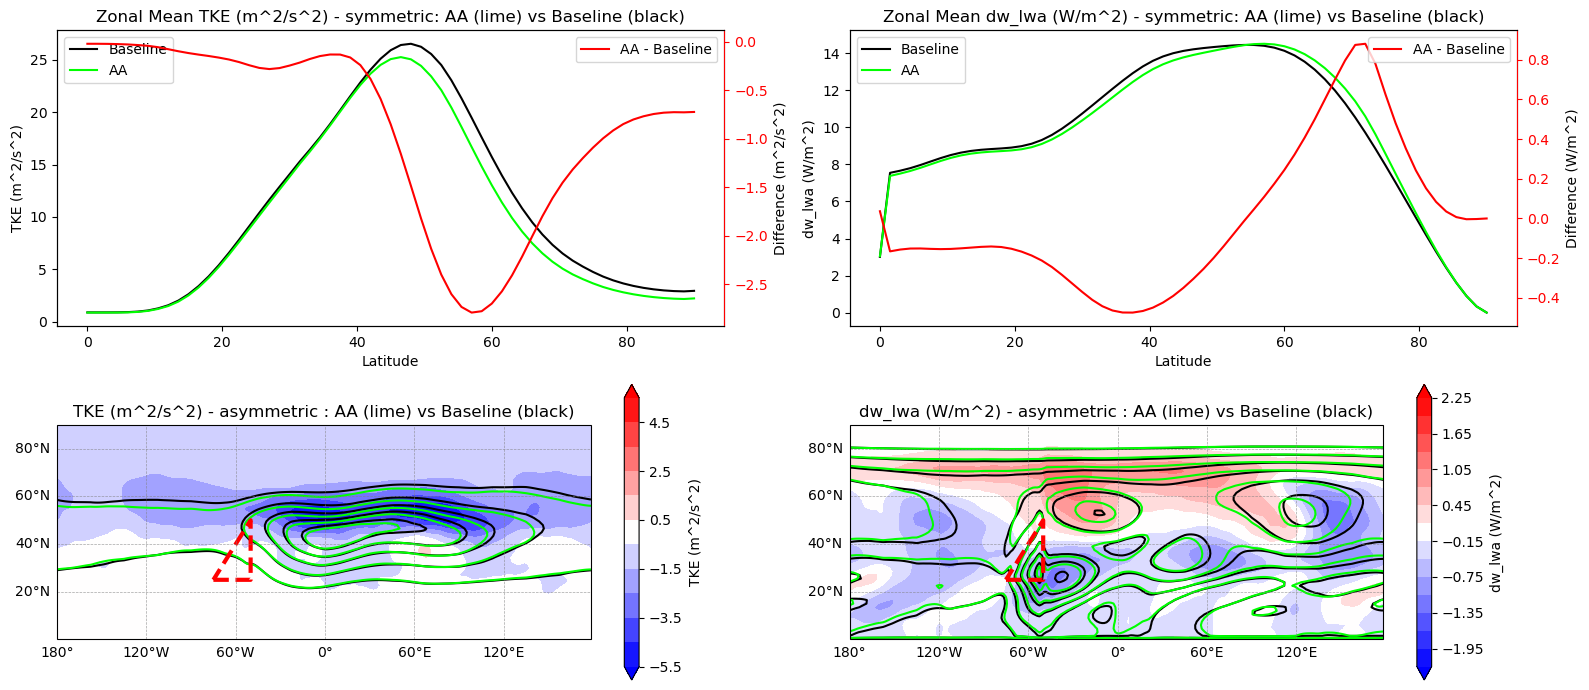

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs

fig = plt.figure(figsize=(16, 7))
gs = fig.add_gridspec(2, 2)
ax0 = fig.add_subplot(gs[0, 0])  # Zonal mean TKE
ax1 = fig.add_subplot(gs[0, 1])  # Zonal mean dw_lwa
ax2 = fig.add_subplot(gs[1, 0], projection=ccrs.PlateCarree())  # TKE 2D field
ax3 = fig.add_subplot(gs[1, 1], projection=ccrs.PlateCarree())  # dw_lwa 2D field

titles = ['symmetric', 'asymmetric']

# Triangle coordinates
coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

# Zonal mean for TKE
ds_a = ds_clims[0]
ds_b = ds_clims[1]
lat = ds_a['lat']
tke_a_zonal = ds_a['tke'].mean(dim='lon')
tke_b_zonal = ds_b['tke'].mean(dim='lon')
tke_diff = tke_b_zonal - tke_a_zonal

ax0.plot(lat, tke_a_zonal, color='black', label='Baseline')
ax0.plot(lat, tke_b_zonal, color='lime', label='AA')
ax0.set_title('Zonal Mean TKE (m^2/s^2) - ' + titles[0] + ': AA (lime) vs Baseline (black)')
ax0.set_xlabel('Latitude')
ax0.set_ylabel('TKE (m^2/s^2)')
ax0.legend(loc='upper left')
ax0_twin = ax0.twinx()
ax0_twin.plot(lat, tke_diff, color='red', label='AA - Baseline')
ax0_twin.set_ylabel('Difference (m^2/s^2)')
ax0_twin.legend(loc='upper right')
ax0_twin.tick_params(axis='y', colors='red')
ax0_twin.spines['right'].set_color('red')

# Zonal mean for dw_lwa
dw_a_zonal = ds_a['dw_lwa'].mean(dim='lon')
dw_b_zonal = ds_b['dw_lwa'].mean(dim='lon')
dw_diff = dw_b_zonal - dw_a_zonal

ax1.plot(lat, dw_a_zonal, color='black', label='Baseline')
ax1.plot(lat, dw_b_zonal, color='lime', label='AA')
ax1.set_title('Zonal Mean dw_lwa (W/m^2) - ' + titles[0] + ': AA (lime) vs Baseline (black)')
ax1.set_xlabel('Latitude')
ax1.set_ylabel('dw_lwa (W/m^2)')
ax1.legend(loc='upper left')
ax1_twin = ax1.twinx()
ax1_twin.plot(lat, dw_diff, color='red', label='AA - Baseline')
ax1_twin.tick_params(axis='y', colors='red')
ax1_twin.spines['right'].set_color('red')
ax1_twin.set_ylabel('Difference (W/m^2)')
ax1_twin.legend(loc='upper right')

ds_a = ds_clims[2]
ds_b = ds_clims[3]

# TKE 2D field (ax2)
levels = np.linspace(0, 100, 10)
levels_diff = np.arange(-5.5, 6, 1)
ax2.set_title(f'TKE (m^2/s^2) - {titles[1]} : AA (lime) vs Baseline (black)')
c1 = ax2.contour(ds_a['lon'], ds_a['lat'], ds_a['tke'], levels=levels, colors='black', transform=ccrs.PlateCarree())
c2 = ax2.contour(ds_b['lon'], ds_b['lat'], ds_b['tke'], levels=levels, colors='lime', transform=ccrs.PlateCarree())
sh = ax2.contourf(ds_a['lon'], ds_a['lat'], ds_b['tke'] - ds_a['tke'], levels=levels_diff, cmap='bwr', alpha=1, extend='both', transform=ccrs.PlateCarree())
fig.colorbar(sh, ax=ax2, orientation='vertical', label='TKE (m^2/s^2)')
ax2.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
ax2.set_aspect(1.6)
gl0 = ax2.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
gl0.top_labels = False
gl0.right_labels = False

# dw_lwa 2D field (ax3)
levels = np.linspace(5, 25, 8)
levels_diff = np.arange(-2.25, 2.3, 0.3)
ax3.set_title(f'dw_lwa (W/m^2) - {titles[1]} : AA (lime) vs Baseline (black)')
c3 = ax3.contour(ds_a['lon'], ds_a['lat'], ds_a['dw_lwa'], levels=levels, colors='black', transform=ccrs.PlateCarree())
c4 = ax3.contour(ds_b['lon'], ds_b['lat'], ds_b['dw_lwa'], levels=levels, colors='lime', transform=ccrs.PlateCarree())
sh2 = ax3.contourf(ds_a['lon'], ds_a['lat'], ds_b['dw_lwa'] - ds_a['dw_lwa'], levels=levels_diff, cmap='bwr', alpha=1, extend='both', transform=ccrs.PlateCarree())
fig.colorbar(sh2, ax=ax3, orientation='vertical', label='dw_lwa (W/m^2)')
ax3.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
ax3.set_aspect(1.6)
gl1 = ax3.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
gl1.top_labels = False
gl1.right_labels = False

plt.tight_layout()
plt.show()